<a href="https://colab.research.google.com/github/kaz3107/IS4487/blob/main/assignment_06_data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [1]:
# Import necessary libraries 🔧
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# Load your uploaded file (path "/content/listings.csv.gz") 🔧
df = pd.read_csv('/content/listings.csv.gz')

df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1188641052152277018,https://www.airbnb.com/rooms/1188641052152277018,20260615212226,2026-06-16,city scrape,Spacious unit at heart of SEA,"Located in the heart of Seattle, This is a stu...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,32542619,...,NaN,NaN,NaN,NaN,NaN,4,4,0,0,NaN
1,849077848951991421,https://www.airbnb.com/rooms/849077848951991421,20260615212226,2026-06-16,city scrape,"Blueground | Central District, gym & bbq, nr d...",Feel at home wherever you choose to live with ...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,107434423,...,NaN,NaN,NaN,NaN,NaN,239,239,0,0,NaN
2,599205596133828323,https://www.airbnb.com/rooms/599205596133828323,20260615212226,2026-06-16,city scrape,purple room,simple room facing front yard in centrally lo...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,48441443,...,5.00,5.00,5.00,NaN,NaN,5,0,5,0,0.06
3,846763,https://www.airbnb.com/rooms/846763,20260615212226,2026-06-16,city scrape,Right at Home in Ravenna,"Our home is a lovely peaceful place, and we wi...",NaN,https://a0.muscache.com/pictures/62990267/b8fe...,4421734,...,4.89,4.89,4.90,NaN,NaN,1,0,1,0,0.51
4,1512026480622905433,https://www.airbnb.com/rooms/1512026480622905433,20260615212226,2026-06-16,city scrape,"3 Min Walk to Capitol Hill Station, Brand New ...",Brand new 3BR/3BA townhome in the heart of Cap...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,44486963,...,4.94,4.89,4.94,STR-OPLI-25-004798,NaN,1,1,0,0,4.30


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

host_acceptance_rate           7769
host_response_time             7769
host_since                     7769
host_total_listings_count      7769
host_verifications             7769
host_response_rate             7769
neighbourhood                  7769
calendar_updated               7769
instant_bookable               7769
host_about                     2422
review_scores_location         1271
review_scores_accuracy         1271
review_scores_communication    1271
reviews_per_month              1271
review_scores_checkin          1271
review_scores_cleanliness      1271
review_scores_value            1271
last_review                    1271
first_review                   1271
review_scores_rating           1271
host_location                  1217
license                        1184
bathrooms                      1122
beds                            859
price                           826
price_quote_total_price         826
estimated_revenue_l365d         826
price_quote_price_per_night 

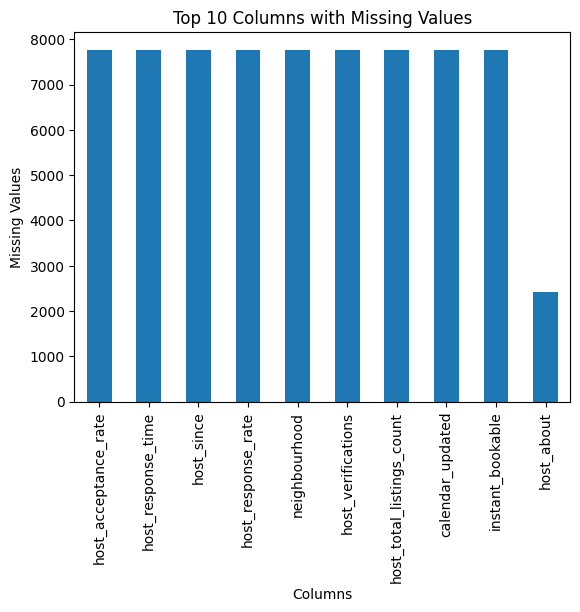

In [15]:
# Count missing values
missing_values = df.isnull().sum()

# Show columns with missing values
print(missing_values[missing_values > 0].sort_values(ascending=False))

# Visualize top 10 missing values
missing_values.sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("Top 10 Columns with Missing Values")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. I noticed that neighborhood_overview, host_since, and host_verifications have the most missing values. Each one has 7,769 missing values.
2. I think missing host_since and host_verifications could create business issues because they provide information about the host and may be useful for understanding host experience or trust.
3. I think neighborhood_overview could be dropped because so much of the column is missing and there are other location columns in the dataset that could still provide information about the listing.


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [7]:
# Drop columns
df = df.drop(columns=['neighborhood_overview', 'host_thumbnail_url', 'host_neighbourhood'])

# Check the data
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1188641052152277018,https://www.airbnb.com/rooms/1188641052152277018,20260615212226,2026-06-16,city scrape,Spacious unit at heart of SEA,"Located in the heart of Seattle, This is a stu...",https://a0.muscache.com/pictures/miso/Hosting-...,32542619,https://www.airbnb.com/users/show/32542619,...,NaN,NaN,NaN,NaN,NaN,4,4,0,0,NaN
1,849077848951991421,https://www.airbnb.com/rooms/849077848951991421,20260615212226,2026-06-16,city scrape,"Blueground | Central District, gym & bbq, nr d...",Feel at home wherever you choose to live with ...,https://a0.muscache.com/pictures/prohost-api/H...,107434423,https://www.airbnb.com/users/show/107434423,...,NaN,NaN,NaN,NaN,NaN,239,239,0,0,NaN
2,599205596133828323,https://www.airbnb.com/rooms/599205596133828323,20260615212226,2026-06-16,city scrape,purple room,simple room facing front yard in centrally lo...,https://a0.muscache.com/pictures/miso/Hosting-...,48441443,https://www.airbnb.com/users/show/48441443,...,5.00,5.00,5.00,NaN,NaN,5,0,5,0,0.06
3,846763,https://www.airbnb.com/rooms/846763,20260615212226,2026-06-16,city scrape,Right at Home in Ravenna,"Our home is a lovely peaceful place, and we wi...",https://a0.muscache.com/pictures/62990267/b8fe...,4421734,https://www.airbnb.com/users/show/4421734,...,4.89,4.89,4.90,NaN,NaN,1,0,1,0,0.51
4,1512026480622905433,https://www.airbnb.com/rooms/1512026480622905433,20260615212226,2026-06-16,city scrape,"3 Min Walk to Capitol Hill Station, Brand New ...",Brand new 3BR/3BA townhome in the heart of Cap...,https://a0.muscache.com/pictures/hosting/Hosti...,44486963,https://www.airbnb.com/users/show/44486963,...,4.94,4.89,4.94,STR-OPLI-25-004798,NaN,1,1,0,0,4.30


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. I dropped neighborhood_overview, host_thumbnail_url, and host_neighbourhood.
2. I think these columns were not very useful because they had a lot of missing values. The neighborhood overview is mostly descriptive text, the host thumbnail URL is mainly a link to an image, and the host neighborhood is less important than the location of the actual listing.
3. I think leaving these columns in could add a lot of missing or unnecessary information to the dataset and make it harder to work with later.

## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [10]:
# Check missing values
df[['bedrooms', 'description']].isnull().sum()

# Fill missing bedrooms with median
df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].median())

# Fill missing descriptions
df['description'] = df['description'].fillna('Unknown')

# Check missing values
df[['bedrooms', 'description']].isnull().sum()

,0
bedrooms,0
description,0


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. I cleaned the bedrooms and description columns.

2. I filled the missing bedroom values with the median because bedrooms is a numeric column. I filled the missing descriptions with "Unknown" because it is a text column.

3. I think one risk is that the filled values may not be the actual values for those listings. Using the median or "Unknown" keeps the data complete, but it does not recover the original information.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

In [12]:
# Clean or adjust your dataset 🔧
# Check price data type
df['price'].dtype

df['price'].head()

# Remove dollar sign and comma
df['price'] = df['price'].str.replace('$', '', regex=False)
df['price'] = df['price'].str.replace(',', '', regex=False)

# Convert price to numeric
df['price'] = pd.to_numeric(df['price'])

# Check the result
df['price'].describe()

,price
count,6943.000000
mean,349.719676
std,465.813269
min,10.180000
25%,171.500000
50%,281.000000
75%,422.240000
max,25916.670000


### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. I fixed the price column because it was stored as an object instead of a numeric type.
2. I removed the dollar signs and commas from the price values and then converted the column to numeric.
3. I think this makes the price data easier to use for calculations and analysis later because it is now stored as numbers.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [13]:
# Check duplicate rows
print(df.duplicated().sum())

# Check duplicate IDs
print(df['id'].duplicated().sum())

0
0


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. I did not find any exact duplicate rows or duplicate listing IDs in the dataset.
2. I did not drop any records because there were no duplicates to remove. I kept all of the listings.
3. I think duplicates could be risky because the same listing could be counted more than once and make the results inaccurate.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [14]:
# export csv here 🔧
df.to_csv('cleaned_airbnb_data_6.csv', index=False)

## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. __ I think the most challenging part was deciding what to do with the missing values. The code was not too difficult, but I had to think about which columns should be dropped and which values should be filled.
2. __ I decided to drop the neighborhood_overview column because it had 7,769 missing values and was mostly descriptive text. I thought it was better to remove it because there were other location columns that could still provide information about the listings.
3. __ I think a pricing analyst could benefit from the cleaned data because the price column is now numeric and easier to use for calculations. The dataset also has fewer unnecessary and missing values to work with.
4. __ If I had more time, I would look more closely at the other columns that still have missing values, especially price and review information. I would also check for unusual values that might affect the analysis.
5. __ I think this assignment relates to my learning outcomes because I practiced reading and changing Python code to clean and summarize data. I also had to look at patterns in the missing values and make decisions about how the data should be cleaned for later business analysis.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"